# **SAMson: An Automated Brain Extraction Tool for Rodents Using SAM**  
*Accurate and robust rodent brain segmentation for MRI data*

---

### **Authored by**  
**Daniel Panadero Soler**<sup>1</sup>, **Mohamed Kotb Selim**<sup>1</sup>, **Patricia Martínez-Tazo**<sup>1</sup>,  
**Emma Muñoz-Moreno**<sup>2</sup>, **Pedro Ramos-Cabrer**<sup>3,4</sup>, **Pilar López-Larrubia**<sup>5</sup>,  
**Silvia De Santis**<sup>1</sup>, **Santiago Canals**<sup>1</sup>, and **Antonio Pertusa**<sup>6</sup>  

<sup>1</sup>Instituto de Neurociencias, CSIC-UMH, Sant Joan d’Alacant, Spain  
<sup>2</sup>IDIBAPS, Barcelona, Spain  
<sup>3</sup>CIC biomaGUNE, BRTA, Donostia–San Sebastián, Spain  
<sup>4</sup>Ikerbasque, Basque Foundation for Science, Bilbao, Spain  
<sup>5</sup>Instituto de Investigaciones Biomédicas Sols-Morreale, CSIC-UAM, Madrid, Spain  
<sup>6</sup>University Institute for Computer Research, University of Alicante, Alicante, Spain  

📧 **Contact**: [pertusa@ua.es](mailto:pertusa@ua.es)  

---

### **Abstract**
**Background and objective.** Accurate brain extraction is a critical step in the analysis of rodent head magnetic resonance imaging (MRI) data. However, current methods often encounter difficulties in handling the diverse range of imaging setups, resolutions, and experimental conditions that are commonly found in this field.  
**Methods.** Based on the Segment Anything Model (SAM), we introduce here SAMson (*SAM for Segmentation Of Neuroimages*), an automated tool for robust rodent brain extraction. SAMson integrates a bounding box generator and a mask prediction pipeline, offering fully automated and semi-automated modes to address varying experimental complexities.  
**Results.** The performance of SAMson was evaluated using seven multi-center rodent MRI [datasets](https://doi.org/10.20350/digitalCSIC/17000) annotated at the pixel level, which differed in terms of acquisition parameters, contrast (T2-weighted, T2\*-weighted and diffusion-weighted images), resolution, anteroposterior coverage and animal age groups. SAMson outperformed the nine methods tested, BET, BET4Animal, RBM, BEN, SHERM, ANTs, deepbet, MedSAM and SAM2, in segmentation accuracy (significantly in 87 of 90 dataset–method comparisons), with mean Jaccard indices of 89.0–94.7%. The semi-automated mode demonstrates particular efficacy in challenging scenarios, including low-resolution images and cases requiring refined mask precision.  
**Conclusions.** In contrast to conventional volumetric techniques, SAMson's errors are confined to a few individual slices, thereby enabling rapid and targeted correction when needed. By providing open-source access, SAMson aims to support large-scale research workflows and advance translational neuroscience. The curated data can be downloaded from https://doi.org/10.20350/digitalCSIC/17000, and the code is available at https://github.com/CanalsLab/SAMson, as an installable Python package (samson-mri) with a command-line interface, a Python API and a graphical application.

---

### **Contents**
This notebook comprises the experiments on SAMson that underpin the evaluations presented in the SAMson article (`SAMson_benchmark.ipynb` evaluates the other tools and `SAMson_figures_and_statistics.ipynb` produces the figures and statistics). Within this notebook, you will find the accuracy assessments conducted across seven datasets (ten dataset-contrasts, 409 scans), encompassing evaluations of:
1. The Full-Auto mode of SAMson.
2. The Semi-Auto mode of SAMson (the best of the 3 candidate masks of each slice is selected with the reference mask).
3. The object detection component of SAMson (box analysis).
4. The oracle performance of SAMson (box prompts derived from the reference masks).

All scans are processed (`datasets/participants.tsv`), re-oriented losslessly to SAMson's orientation with the AP setting and median_otsu values of their dataset-contrast (`datasets/dataset_settings.json`), and evaluated on every slice with brain in the reference mask, in every dataset. By default (`REGENERATE = False`) the masks and boxes of the full run (`outputs/`) are loaded; `REGENERATE = True` runs SAMson again (each slice embedded once for the four experiments) and checks that they are identical. The metrics of every slice and scan are saved to `results/exp_samson_slices.csv` and `results/exp_samson_subjects.csv` (read by `SAMson_figures_and_statistics.ipynb`); at the end they are compared with those of the full run (`results/subjects.csv`, `results/boxes.csv`). After each dataset-contrast, the slices of its median scan (the scan whose Full-Auto Jaccard index, the mean over its evaluated slices, is closest to the median of the dataset-contrast; ties: first scan id in sorted order) are shown with SAMson's slice grid, as in `SAMson.ipynb`: Full-Auto masks, then Semi-Auto masks. With `PLOTS = True`, the slices of the median scan of each approach (same rule) are also plotted (not done by default, to limit the file size).

## Setup

In [ ]:
import os                                                                       # files
import json                                                                     # dataset settings
import time                                                                     # progress
import warnings                                                                 # warnings
import cv2                                                                      # images  # type: ignore
import matplotlib.pyplot as plt                                                 # plots
import numpy as np                                                              # arrays
import pandas as pd                                                             # tables
import nibabel as nib                                                           # nifti  # type: ignore
import torch                                                                    # SAM backend  # type: ignore
from os.path import join as pjoin                                               # join paths
from matplotlib.font_manager import FontProperties                              # plot titles
from segment_anything import sam_model_registry, SamPredictor                   # SAM  # type: ignore
from skimage.morphology import binary_closing, binary_erosion, binary_dilation  # mask processing
from scipy import ndimage                                                       # image processing
from dipy.segment.mask import median_otsu                                       # Otsu method  # type: ignore
warnings.filterwarnings("ignore", category=FutureWarning)                       # torch.load notice

"""""  INPUTS  (ADAPT  FOLLOWING  LINES)  """""

# ------------------           PATHS           ------------------ #
root_path      = os.path.abspath("..")                                            # Release folder (this notebook is in <release>/notebooks)
datasets_path  = pjoin(root_path, "datasets")                                     # Images, reference masks, participants.tsv, dataset_settings.json
template_path  = pjoin(datasets_path, "template", "anat_template_FP.nii.gz")      # Template file
results_path   = pjoin(root_path, "results")                                      # Metrics (CSV) of all experiments
outputs_path   = pjoin(root_path, "outputs")                                      # Masks and boxes of the full run (reproducibility check)
checkpoints    = os.path.expanduser(os.environ.get("SAMSON_CHECKPOINTS", "~/.cache/samson_mri"))  # Folder with sam_vit_h_4b8939.pth (REGENERATE only)
SUBSET         = None                                                             # Scans per dataset-contrast (None: all; e.g. 2 for a quick test)
REGENERATE     = False   # True: run SAMson on every scan (about 70 min on the GPU) and check the masks and boxes against outputs/; False: load them from outputs/
PLOTS          = False   # True: also plot the slices of the median scan of each dataset-contrast and approach (Full-Auto, Semi-Auto, box analysis, Oracle)
os.makedirs(results_path, exist_ok=True)

"""""""""   SEGMENT  ANYTHING  MODEL   """""""""

device    = "cuda" if torch.cuda.is_available() else "cpu"
predictor = SamPredictor(sam_model_registry["vit_h"](checkpoint=pjoin(checkpoints, "sam_vit_h_4b8939.pth")).to(device=device)) if REGENERATE else None

### SAMson functions
Identical to the functions of `SAMson.ipynb`.

In [ ]:
"""""""""       IMAGE  AND  MASK  UTILITIES       """""""""

def load_volume(path, reorient=False):
    """
    Load a NIfTI image as a float64 3D array (a trailing singleton 4th dimension is dropped).
    reorient=True flips the z-axis, for images whose anteroposterior axis goes from rostral to caudal.
    """
    volume = nib.load(path).get_fdata()
    if volume.ndim > 3: volume = np.squeeze(volume, axis=-1)
    return np.flip(volume, axis=2) if reorient else volume

def to_rgb(slice_2d):
    """Rotate a slice and convert it to the 8-bit RGB image SAM expects (normalised by the slice maximum)."""
    image = np.rot90(slice_2d).astype(np.float32)
    return cv2.cvtColor(((image / np.max(image)) * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)

def evaluate(mask, reference):
    """
    Accuracy (%), Jaccard index and Dice coefficient of a mask against a reference mask (0 if the reference is empty).
    Accuracy is 100 minus the percentage of disagreeing pixels relative to the reference mask size.
    """
    sam, ref = mask.astype(int), reference.astype(int)
    total = ref + sam
    if not (np.any(ref) and np.any(total)):
        return 0, 0, 0
    overlap = np.count_nonzero(total == 2)
    accuracy = 100 - round((np.count_nonzero(ref - sam) / np.count_nonzero(ref)) * 100, 2)
    jaccard  = round((overlap / np.count_nonzero(total)), 4)
    dice     = round(2 * (overlap / (np.count_nonzero(sam) + np.count_nonzero(ref))), 4)
    return accuracy, jaccard, dice

def evaluate_slices(masks, reference, slices=None):
    """
    Metrics of every candidate mask of every slice (or of the given slice indexes) against the reference volume.
    Returns a table with 1-based slice numbers (as in the plots) and 0-based candidate indexes (as in best_mask_indexes).
    """
    slices = range(len(masks)) if slices is None else slices
    rows = [(s + 1, c, *evaluate(masks[s, c], np.rot90(reference[:, :, s]))) for s in slices for c in range(masks.shape[1])]
    return pd.DataFrame(rows, columns=["slice", "candidate", "accuracy", "jaccard", "dice"])

def subject_means(metrics):
    """Subject mean accuracy, Jaccard and Dice over slices, rounded as in the article."""
    return {m: round(sum(metrics[m]) / len(metrics), d) for m, d in (("accuracy", 2), ("jaccard", 4), ("dice", 4))}

def find_best_mask_indexes(metrics):
    """Index (0, 1 or 2) of the candidate with the highest Jaccard index in each slice (first one if tied)."""
    return metrics.pivot(index="slice", columns="candidate", values="jaccard").to_numpy().argmax(axis=1).tolist()

def keep_largest_component(mask):
    """Keep only the largest connected component of a binary mask (returned as 0/1 integers)."""
    labels, _ = ndimage.label(mask)  # type: ignore
    return np.where(labels == np.argmax(np.bincount(labels.ravel())[1:]) + 1, 1, 0)

def remove_lobes_and_separate_pixels(mask, otsu=False):
    """
    Remove lobes (regions that detach from the main body after an erosion) and isolated pixel groups from a binary
    mask, with increasing footprint sizes (larger ones for the Otsu mask), keeping the largest connected component.
    """
    if np.any(mask):
        for size in ([2, 5, 20] if otsu else [1, 2, 3]):
            footprint = np.ones((size, size))
            eroded = binary_erosion(mask, footprint=footprint)
            if np.any(eroded):
                lobes = eroded.copy()
                lobes[keep_largest_component(eroded) == 1] = 0  # Eroded regions other than the main body
                mask = np.where(mask == True, 1, 0) - np.where(binary_dilation(lobes, footprint=footprint) == True, 1, 0)
            mask = keep_largest_component(mask)
    return mask

def postprocess(mask):
    """SAMson post-processing of a SAM mask: lobe and isolated pixel removal followed by a 2x2 closing."""
    return binary_closing(remove_lobes_and_separate_pixels(mask), footprint=np.ones((2, 2)))

def print_percent_done(index, total, bar_len=20):
    """Display a progress bar that updates on the same line."""
    percent_done = round((index + 1) / total * 100, 1)
    done = round(percent_done / (100 / bar_len))
    bar = f"[{'◼' * done}{' ' * (bar_len - done)}] {percent_done}%"
    if percent_done < 100:
        print(f'⏳  {bar}', end='\r')
    else:
        print(f'✅  {bar}', end=' ')


"""""""""       INPUT  PROMPT  GENERATION       """""""""

def bounding_boxes(volume, threshold=0.5):
    """Box [x_left, y_up, x_right, y_down] around the voxels above threshold in every rotated slice ([0, 0, 0, 0] if none)."""
    boxes = []
    for i in range(volume.shape[2]):
        idx = np.argwhere(np.rot90(volume[:, :, i]) > threshold)
        boxes.append([idx[:, 1].min(), idx[:, 0].min(), idx[:, 1].max(), idx[:, 0].max()] if np.any(idx) else [0, 0, 0, 0])
    return np.array(boxes)

def template_relative_coordinates(template_path):
    """
    Brain box of every template slice relative to the box of the template central slice: distances [left, up, right,
    down] from the central box centre, as fractions of the central box width and height.
    """
    edges = bounding_boxes(nib.load(template_path).get_fdata())
    xl, yu, xr, yd = edges[round(len(edges) / 2)]
    width_x, width_y = xr - xl, yd - yu
    central_x, central_y = xl + width_x / 2, yu + width_y / 2
    return np.column_stack([(central_x - edges[:, 0]) / width_x, (central_y - edges[:, 1]) / width_y,
                            (edges[:, 2] - central_x) / width_x, (edges[:, 3] - central_y) / width_y])

def generate_boxes(volume, median_radius, numpass, initial_slice, final_slice):
    """
    Box prompts [x_left, y_up, x_right, y_down] for every slice of a subject: the template box shapes, linearly
    interpolated along the anteroposterior range [initial_slice, final_slice] of the template, are scaled and centred
    on the box of the brain found by median_otsu in the subject's central slice.
    """
    z_template = np.linspace(0, 1, len(relative_coordinates))
    z_subject  = np.linspace(z_template[initial_slice], z_template[final_slice], volume.shape[2])

    # Interpolate the template relative coordinates at each subject slice (nearest slice if z matches exactly)
    previous = np.searchsorted(z_template, z_subject, side='right') - 1
    following = np.searchsorted(z_template, z_subject, side='left')
    with np.errstate(divide='ignore', invalid='ignore'):
        coordinates = relative_coordinates[previous] + (z_subject - z_template[previous])[:, None] * (
            (relative_coordinates[following] - relative_coordinates[previous]) / (z_template[following] - z_template[previous])[:, None])
    exact = previous == following
    coordinates[exact] = relative_coordinates[np.abs(z_template[None, :] - z_subject[exact, None]).argmin(axis=1)]

    # Brain box of the subject's central slice from the cleaned median_otsu mask
    _, otsu = median_otsu(volume, median_radius=median_radius, numpass=numpass)
    central_mask = remove_lobes_and_separate_pixels(np.rot90(otsu[:, :, np.abs(z_subject - 0.5).argmin()]), otsu=True)
    idx = np.argwhere(central_mask != 0)
    xl, yu, xr, yd = (idx[:, 1].min(), idx[:, 0].min(), idx[:, 1].max(), idx[:, 0].max()) if np.any(idx) else (0, 0, 0, 0)
    width_x, width_y = xr - xl, yd - yu
    central_x, central_y = xl + width_x / 2, yu + width_y / 2

    return np.column_stack([central_x - width_x * coordinates[:, 0], central_y - width_y * coordinates[:, 1],
                            central_x + width_x * coordinates[:, 2], central_y + width_y * coordinates[:, 3]])


"""""""""       MASK  PREDICTION       """""""""

def segment_volume(volume, prompt_sets, model=None, show_progress=True):
    """
    Predict and post-process SAM masks for every slice of a volume.
    prompt_sets is a list of (boxes, multimask_output) pairs: each slice is embedded once and reused for all of them.
    Returns, for each pair, an array (n_slices, 1 or 3 candidates, H, W) of binary masks.
    """
    model = model or predictor
    results = [[] for _ in prompt_sets]
    for s in range(volume.shape[2]):
        if show_progress: print_percent_done(s, volume.shape[2])
        model.set_image(to_rgb(volume[:, :, s]))  # type: ignore
        for result, (boxes, multimask) in zip(results, prompt_sets):
            masks, _, _ = model.predict(point_coords=None, point_labels=None, box=np.array(boxes[s])[None, :], multimask_output=multimask)  # type: ignore
            result.append([postprocess(mask) for mask in masks])
    return [np.array(result) for result in results]

def save_nifti_mask(mask_slices, reference_nifti, path, reorient=False):
    """Save one mask per slice (in plotting orientation) as a uint8 NIfTI aligned voxel-to-voxel with the input image."""
    volume = np.stack([np.rot90(mask, k=-1) for mask in mask_slices], axis=2).astype(np.uint8)  # Undo the slice rotation
    if reorient: volume = np.flip(volume, axis=2)  # Back to the anteroposterior order of the input image
    nifti = nib.Nifti1Image(volume, reference_nifti.affine, reference_nifti.header)
    nifti.set_data_dtype(np.uint8)
    nib.save(nifti, path)


"""""""""       PLOTTING  FUNCTIONS       """""""""

def show_box(box, ax):
    """Plot SAM's input box."""
    ax.add_patch(plt.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], edgecolor='green', facecolor=(0,0,0,0), lw=2))  # type: ignore

def show_mask(mask, ax, manual=False):
    """Plot a SAMson (blue) or reference (yellow) mask."""
    color = np.array([255/255, 234/255, 0/255, 0.6]) if manual else np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))

def slice_panel_size(image_shape, figsize=None, ncols=1, tight=False):
    """Size (inches) of a slice in the former one-figure-per-slice plots, so that the grid keeps it."""
    fig, axs = plt.subplots(1, ncols, figsize=figsize)
    for ax in np.atleast_1d(axs):
        ax.imshow(np.zeros(image_shape)); ax.set_title("Slice", fontsize=10); ax.axis('off')
    if tight: fig.tight_layout()
    ax = np.atleast_1d(axs)[0]
    ax.apply_aspect()
    size = ax.get_position().width * fig.get_figwidth(), ax.get_position().height * fig.get_figheight()
    plt.close(fig)
    return size

def plot_grid(volume, masks, boxes=None, reference=None, ncols=3, dpi=50, figsize=None, tight=False, title_size=10):
    """
    Plot every slice with its candidate mask(s) (blue), reference mask (yellow) and box prompt (green) in one figure,
    left to right and top to bottom; each panel keeps the size it had in the former one-figure-per-slice plots
    (figsize/tight describe that former layout). With several candidates per slice, each row shows one slice.
    """
    n_slices, n_candidates = masks.shape[:2]
    images = [to_rgb(volume[:, :, s]) for s in range(n_slices)]
    w, h = slice_panel_size(images[0].shape, figsize, n_candidates, tight)
    gap_x, gap_y = 0.1, (FontProperties(size=title_size).get_size_in_points() * 1.4 + 8) / 72
    nrows = -(-n_slices * n_candidates // ncols)
    W, H = ncols * w + (ncols - 1) * gap_x, nrows * (h + gap_y)
    fig = plt.figure(figsize=(W, H), dpi=dpi)
    for k in range(n_slices * n_candidates):
        (s, c), (row, col) = divmod(k, n_candidates), divmod(k, ncols)
        ax = fig.add_axes([col * (w + gap_x) / W, 1 - (row + 1) * (h + gap_y) / H, w / W, h / H])
        ax.imshow(images[s])
        ax.set_title(f"Slice #{s + 1}" + (f" - {c + 1}" if n_candidates > 1 else ""), fontsize=title_size)
        ax.axis('off')
        if reference is not None: show_mask(np.rot90(reference[:, :, s]), ax, manual=True)
        show_mask(masks[s, c], ax)
        if boxes is not None: show_box(boxes[s], ax)
    plt.show()

### Experiment functions

In [ ]:
"""""""""       DATASETS       """""""""

settings     = json.load(open(pjoin(datasets_path, "dataset_settings.json")))   # Orientation, AP setting and median_otsu per dataset-contrast
participants = pd.read_csv(pjoin(datasets_path, "participants.tsv"), sep="\t", dtype=str, keep_default_na=False)  # One row per scan
DATASETS = [key for key in settings if key != "conventions"]                     # Dataset-contrasts: D1_T2w, D2_T2w, ..., D7_T2w
GROUPS   = ["3", "4.5", "6", "12"] + DATASETS[1:]                                # D1 ages and the other nine dataset-contrasts
METRICS  = ["accuracy", "jaccard", "dice"]

def subjects(dataset):
    """Yield (group, participants row) for every scan of a dataset-contrast (group: D1 age, otherwise the dataset-contrast)."""
    rows = participants[participants.dataset + "_" + participants.contrast == dataset]
    for _, row in rows.head(SUBSET or len(rows)).iterrows():
        yield (row.group if row.dataset == "D1" else dataset), row

def samson_settings(dataset, n_slices):
    """SAMson AP setting (template slices t0, t1 of generate_boxes) and median_otsu (radius, passes) of a dataset-contrast."""
    ap = next(a for a in settings[dataset]["samson_ap"] if a["n_slices"] == n_slices)
    otsu = next(o for o in settings[dataset]["median_otsu"] if o["n_slices"] == n_slices)
    assert ap["image_slices"] == [0, n_slices - 1]  # SAMson processes every slice in every dataset-contrast
    return ap["template_slices"], (otsu["median_radius"], otsu["numpass"])

def to_canonical(volume, dataset):
    """Stored (raw) -> canonical orientation of SAMson and the template (lossless): axes permuted (perm), then reversed (flips)."""
    perm, flips = settings[dataset]["canonical"]["perm"], settings[dataset]["canonical"]["flips"]
    volume = np.transpose(volume, perm)
    for axis in np.flatnonzero(flips):
        volume = np.flip(volume, axis)
    return np.ascontiguousarray(volume)

def to_raw(volume, dataset):
    """Canonical -> stored (raw) orientation (inverse of to_canonical), to compare a mask with the saved masks."""
    perm, flips = settings[dataset]["canonical"]["perm"], settings[dataset]["canonical"]["flips"]
    for axis in np.flatnonzero(flips):
        volume = np.flip(volume, axis)
    return np.transpose(volume, np.argsort(perm))

def evaluated_slices(dataset, reference):
    """Indexes of the evaluated slices (dataset_settings.json): every slice with brain in the reference mask ("ap_with_reference"), or a fixed list."""
    rule = settings[dataset]["evaluated_slices"]
    if rule["rule"] == "fixed":
        return rule["slices"][str(reference.shape[2])]
    return [s for s in range(reference.shape[2]) if reference[:, :, s].any()]  # "ap_with_reference" (SAMson's AP range = all slices)

def voxel_size(dataset, image_path):
    """Real voxel size (mm; header voxel size / 10) along the axes of the stacked rotated slices (slice, row, column)."""
    zooms = np.array(nib.load(image_path).header.get_zooms()[:3], dtype=float)[settings[dataset]["canonical"]["perm"]] / 10
    return zooms[[2, 1, 0]]


"""""""""       3D  METRICS       """""""""

def hd95(a, b, spacing):
    """Symmetric 95th percentile Hausdorff distance (mm) between the surfaces of two binary volumes."""
    if not a.any() or not b.any():
        return np.nan
    surface_a, surface_b = a ^ ndimage.binary_erosion(a), b ^ ndimage.binary_erosion(b)
    a_to_b = ndimage.distance_transform_edt(~surface_b, sampling=spacing)[surface_a]  # type: ignore
    b_to_a = ndimage.distance_transform_edt(~surface_a, sampling=spacing)[surface_b]  # type: ignore
    return max(np.percentile(a_to_b, 95), np.percentile(b_to_a, 95))

def volume_metrics(masks, reference, slices, spacing):
    """3D Jaccard and Dice, HD95 (mm) and volume bias (%) of the masks (rotated slices) over the evaluated slices."""
    pred = np.stack([masks[s] for s in slices]).astype(bool)
    ref = np.stack([np.rot90(reference[:, :, s]) for s in slices]) > 0.5
    overlap, union = (pred & ref).sum(), (pred | ref).sum()
    return dict(jaccard_3d=overlap / union, dice_3d=2 * overlap / (pred.sum() + ref.sum()),
                hd95_mm=hd95(pred, ref, spacing), volume_bias_pct=100 * (pred.sum() - ref.sum()) / ref.sum())


"""""""""       RESULTS  STORAGE       """""""""

slice_results, subject_results, check_results = [], [], []
ID_COLUMNS = ["method", "dataset", "contrast", "group", "subject", "session", "animal", "scan"]

def add_results(method, group, row, metrics, masks=None, reference=None, spacing=None, **columns):
    """
    Store the per-slice metrics of a scan (slices 1-based) and its summary: slice-mean accuracy, Jaccard and Dice
    (not rounded, as results/subjects.csv), number of failed slices (Jaccard < 0.5) and, if the masks are given, the 3D metrics.
    """
    ids = dict(method=method, dataset=row.dataset, contrast=row.contrast, group=group, subject=row.subject,
               session=row.session, animal=row.animal, scan=os.path.basename(row.image)[:-7])
    slice_results.append(metrics.drop(columns="candidate").assign(**ids, **columns))
    summary = dict(**ids, n_slices=len(metrics), **{m: metrics[m].mean() for m in METRICS}, failed_slices=int((metrics.jaccard < 0.5).sum()))
    if masks is not None:
        summary.update(volume_metrics(masks, reference, metrics.slice - 1, spacing))
    subject_results.append(summary)

def save_results(name):
    """Write all stored per-slice and per-scan results to results/<name>_slices.csv and results/<name>_subjects.csv."""
    slices = pd.concat(slice_results, ignore_index=True)
    slices = slices[ID_COLUMNS + ["slice"] + [c for c in slices if c not in ID_COLUMNS + ["slice"]]]
    slices.to_csv(pjoin(results_path, f"{name}_slices.csv"), index=False)
    pd.DataFrame(subject_results).to_csv(pjoin(results_path, f"{name}_subjects.csv"), index=False)
    print(f"Saved {len(slices)} slice rows and {len(subject_results)} subject rows to {os.path.relpath(results_path, root_path)}/{name}_*.csv")

In [ ]:
"""""""""       EXPERIMENTS       """""""""

relative_coordinates = template_relative_coordinates(template_path)  # Template box shapes used by generate_boxes

def box_analysis(boxes, reference, slices):
    """
    Masks of the box prompts and of the reference boxes (bounding box of the reference mask) of every slice, both with
    end-exclusive edges as in the article's box analysis, and the metrics of the box prompts in the evaluated slices.
    """
    box_masks, reference_boxes = [], []
    for s, box in enumerate(boxes):
        ref = np.rot90(reference[:, :, s])
        box_mask, ref_box = np.zeros_like(ref), np.zeros_like(ref)
        xl, yu, xr, yd = (max(0, round(c)) for c in box)  # Box edges outside the image clipped to it
        box_mask[yu:yd, xl:xr] = 1
        idx = np.argwhere(ref != 0)
        if np.any(idx):
            (yu, xl), (yd, xr) = idx.min(axis=0), idx.max(axis=0)
            ref_box[yu:yd, xl:xr] = 1
        box_masks.append(box_mask)
        reference_boxes.append(ref_box)
    metrics = pd.DataFrame([(s + 1, 0, *evaluate(box_masks[s], reference_boxes[s])) for s in slices],
                           columns=["slice", "candidate", "accuracy", "jaccard", "dice"])
    return np.array(box_masks)[:, None], np.stack([np.rot90(b, k=-1) for b in reference_boxes], axis=2), metrics

selection = pd.read_csv(pjoin(outputs_path, "semi_auto_selection.csv")).set_index("stem")  # Semi-Auto choice of the full run (slices 1-based)

def load_masks(dataset, row, method):
    """Mask of the full run (outputs/masks) as rotated slices (n_slices, 1, H, W), as returned by segment_volume."""
    path = pjoin(outputs_path, "masks", f"samson_{method}", os.path.dirname(row.image), f"{os.path.basename(row.image)[:-7]}_mask.nii.gz")
    volume = to_canonical(load_volume(path), dataset) > 0.5
    return np.array([np.rot90(volume[:, :, s]) for s in range(volume.shape[2])])[:, None]

def check_masks(dataset, row, boxes, masks):
    """Masks (mapped back to the stored orientation) and boxes against those of the full run (outputs/)."""
    scan, folder = os.path.basename(row.image)[:-7], os.path.dirname(row.image)
    compared = []
    for method, mask_slices in masks.items():
        mask = to_raw(np.stack([np.rot90(m, k=-1) for m in mask_slices[:, 0]], axis=2), dataset) > 0  # Undo the slice rotation
        compared.append((f"samson_{method}", mask, pjoin(outputs_path, "masks", f"samson_{method}", folder, f"{scan}_mask.nii.gz")))
    for check, mask, path in compared:
        saved = load_volume(path) > 0.5
        same_shape = mask.shape == saved.shape
        check_results.append(dict(check=check, dataset=dataset, scan=scan, identical=same_shape and np.array_equal(mask, saved),
                                  differing_voxels=int((mask != saved).sum()) if same_shape else np.nan))
    saved = np.load(pjoin(outputs_path, "boxes", folder, f"{scan}_boxes.npy"))
    check_results.append(dict(check="boxes", dataset=dataset, scan=scan, identical=boxes.shape == saved.shape and np.array_equal(boxes, saved),
                              differing_voxels=np.nan))

def run_experiments(dataset):
    """Full-Auto, Semi-Auto, box analysis and Oracle experiments on every scan of a dataset-contrast."""
    plotted = {}
    for group, row in subjects(dataset):
        start_time = time.time()
        image_path, scan = pjoin(datasets_path, row.image), os.path.basename(row.image)[:-7]
        volume = to_canonical(load_volume(image_path), dataset)
        reference = to_canonical(load_volume(pjoin(datasets_path, row["mask"])), dataset)
        spacing = voxel_size(dataset, image_path)
        slices = evaluated_slices(dataset, reference)
        template_slices, otsu = samson_settings(dataset, volume.shape[2])

        oracle_boxes = bounding_boxes(reference)  # Oracle: box prompts of the reference mask
        if REGENERATE:
            # SAM masks of the three experiments from a single embedding per slice
            boxes = generate_boxes(volume, *otsu, *template_slices)
            full, candidates, oracle = segment_volume(volume, [(boxes, False), (boxes, True), (oracle_boxes, False)], show_progress=False)

            # Semi-Auto: best of the 3 candidates of each slice according to the reference mask
            best = find_best_mask_indexes(evaluate_slices(candidates, reference))
            semi = candidates[np.arange(len(candidates)), best][:, None]
        else:
            # Masks, boxes and Semi-Auto choice of the full run (the 3 candidate masks are not stored)
            boxes = np.load(pjoin(outputs_path, "boxes", os.path.dirname(row.image), f"{scan}_boxes.npy"))
            full, semi, oracle = (load_masks(dataset, row, method) for method in ("full_auto", "semi_auto", "oracle"))
            candidates, best = None, selection.loc[[scan]].sort_values("slice").selected_candidate.tolist()
            assert len(best) == volume.shape[2]
        box_masks, reference_boxes, box_metrics = box_analysis(boxes, reference, slices)

        # Metrics, and comparison of the masks and boxes with the saved ones (REGENERATE)
        for method, masks in (("full_auto", full), ("semi_auto", semi), ("oracle", oracle)):
            extra = dict(selected_candidate=[best[s] for s in slices]) if method == "semi_auto" else {}
            add_results(method, group, row, evaluate_slices(masks, reference, slices), masks[:, 0], reference, spacing, **extra)
        add_results("box", group, row, box_metrics)
        if REGENERATE:
            check_masks(dataset, row, boxes, dict(full_auto=full, semi_auto=semi, oracle=oracle))
        jaccards = {r["method"]: r["jaccard"] for r in subject_results[-4:]}
        print(f"{group:>10} | {scan:<44} | Jaccard  Full-Auto {jaccards['full_auto']:.4f}  Semi-Auto {jaccards['semi_auto']:.4f}  "
              f"Box {jaccards['box']:.4f}  Oracle {jaccards['oracle']:.4f} | {time.time() - start_time:.0f} s")
        plotted[scan] = dict(volume=volume, reference=reference, boxes=boxes, oracle_boxes=oracle_boxes, full=full, candidates=candidates,
                             best=best, semi=semi, box_masks=box_masks, reference_boxes=reference_boxes, oracle=oracle)

    # Slices of the median scan of each approach (median_scan)
    if not PLOTS:
        return
    table = pd.DataFrame(subject_results)
    table = table[table.dataset + "_" + table.contrast == dataset]
    for method in ("full_auto", "semi_auto", "box", "oracle"):
        ranked = table[table.method == method]
        median = median_scan(ranked)
        p = plotted[median.scan]
        figures = dict(
            full_auto=[("Full-Auto", (p["full"], p["boxes"], p["reference"]), dict(dpi=50))],
            semi_auto=[("Semi-Auto candidates", (p["candidates"], p["boxes"], p["reference"]), dict(dpi=plt.rcParams['figure.dpi'], figsize=(7, 11), tight=True)),
                       (f"Semi-Auto selection {p['best']}", (p["semi"], p["boxes"], p["reference"]), dict(dpi=70, title_size=plt.rcParams['axes.titlesize']))],
            box=[("Box analysis (blue: box prompt, yellow: reference box)", (p["box_masks"], None, p["reference_boxes"]), dict(dpi=70, title_size=plt.rcParams['axes.titlesize']))],
            oracle=[("Oracle", (p["oracle"], p["oracle_boxes"], p["reference"]), dict(dpi=50))])
        for title, args, kwargs in figures[method]:
            print(f"\n{title} - {median.scan} (median scan of {len(ranked)} scans: Jaccard {median.jaccard:.4f})")
            if args[0] is None:
                print("Not plotted: the candidate masks are not stored (REGENERATE = True plots them).")
                continue
            plot_grid(p["volume"], *args, **kwargs)  # type: ignore


"""""""""       MEDIAN  SCAN       """""""""

def median_scan(table):
    """
    Row of the median scan of per-scan results (one method, one dataset-contrast): the scan whose Jaccard index (mean over
    its evaluated slices) is closest to the median of the scans. Ties, such as the two middle scans of an even number of
    scans (equidistant up to floating-point error), go to the first scan id in sorted order.
    """
    table = table.sort_values("scan")
    distance = (table.jaccard - table.jaccard.median()).abs()
    return table[distance <= distance.min() + 1e-12].iloc[0]

def plot_median_scan(dataset, dpi=50):
    """
    Slices of the median Full-Auto scan of a dataset-contrast (median_scan of the Full-Auto results of run_experiments) in
    SAMson's slice grid (plot_grid, as in SAMson.ipynb): Full-Auto masks, then Semi-Auto masks (best candidate of each
    slice), in blue, with the box prompts (green) and the reference mask (yellow). Masks and boxes of the full run (outputs/).
    """
    table = pd.DataFrame(subject_results)
    table = table[table.dataset + "_" + table.contrast == dataset]
    full = table[table.method == "full_auto"]
    scan = median_scan(full).scan
    jaccard = table[table.scan == scan].set_index("method").jaccard
    row = next(row for _, row in subjects(dataset) if os.path.basename(row.image)[:-7] == scan)
    volume = to_canonical(load_volume(pjoin(datasets_path, row.image)), dataset)
    reference = to_canonical(load_volume(pjoin(datasets_path, row["mask"])), dataset)
    boxes = np.load(pjoin(outputs_path, "boxes", os.path.dirname(row.image), f"{scan}_boxes.npy"))
    print(f"Median scan of {dataset} (median Full-Auto Jaccard of {len(full)} scans: {100 * full.jaccard.median():.2f}%): {scan} | "
          f"Jaccard  Full-Auto {100 * jaccard['full_auto']:.2f}%  Semi-Auto {100 * jaccard['semi_auto']:.2f}%")
    for method, name in (("full_auto", "Full-Auto"), ("semi_auto", "Semi-Auto")):
        print(f"\n{name} masks - {scan}")
        plot_grid(volume, load_masks(dataset, row, method), boxes, reference, dpi=dpi)

# Experiments
Full-Auto, Semi-Auto, box analysis and Oracle for every scan. Each line reports the scan mean Jaccard index of the evaluated slices. The second cell of each dataset-contrast shows the slices of its median scan (`plot_median_scan`): Full-Auto masks, then Semi-Auto masks (blue), with the box prompts (green) and the reference mask (yellow).

## D1_T2w

In [5]:
run_experiments("D1_T2w")

         3 | sub-A110123_T2w                              | Jaccard  Full-Auto 0.9120  Semi-Auto 0.9529  Box 0.8091  Oracle 0.9500 | 0 s
         3 | sub-A120123_T2w                              | Jaccard  Full-Auto 0.8754  Semi-Auto 0.9190  Box 0.7515  Oracle 0.9338 | 0 s
         3 | sub-A130123_T2w                              | Jaccard  Full-Auto 0.9475  Semi-Auto 0.9531  Box 0.7864  Oracle 0.9517 | 0 s
         3 | sub-A160123_T2w                              | Jaccard  Full-Auto 0.8876  Semi-Auto 0.9296  Box 0.7518  Oracle 0.9460 | 0 s
         3 | sub-A170123_T2w                              | Jaccard  Full-Auto 0.8696  Semi-Auto 0.9309  Box 0.7970  Oracle 0.9344 | 0 s
         3 | sub-B110123_T2w                              | Jaccard  Full-Auto 0.9006  Semi-Auto 0.9310  Box 0.7633  Oracle 0.9390 | 0 s
         3 | sub-B120123_T2w                              | Jaccard  Full-Auto 0.8662  Semi-Auto 0.8968  Box 0.7766  Oracle 0.9322 | 0 s
         3 | sub-B130123_T2w             

Median scan of D1_T2w (median Full-Auto Jaccard of 53 scans: 89.99%): sub-A030222_T2w | Jaccard  Full-Auto 89.99%  Semi-Auto 92.44%

Full-Auto masks - sub-A030222_T2w


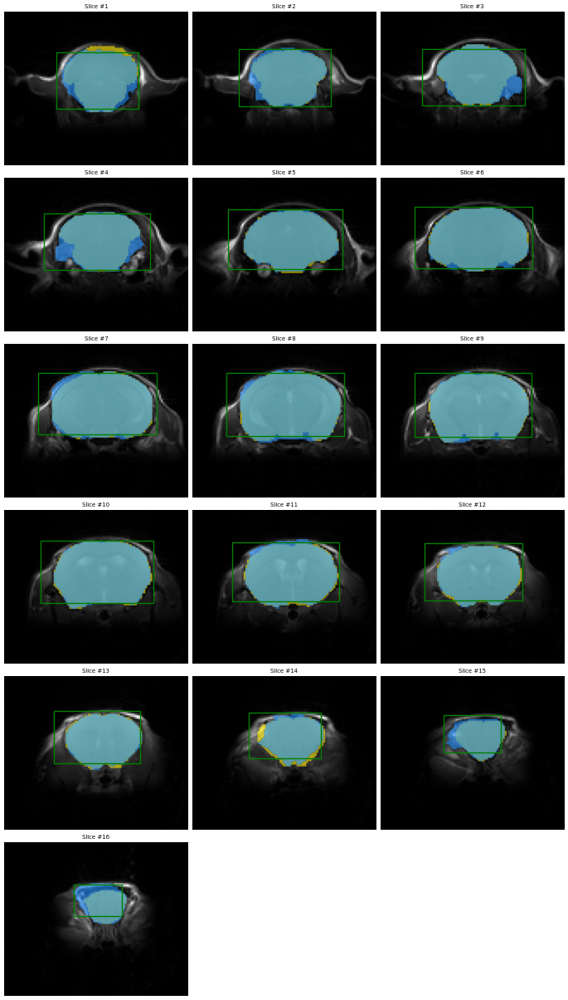


Semi-Auto masks - sub-A030222_T2w


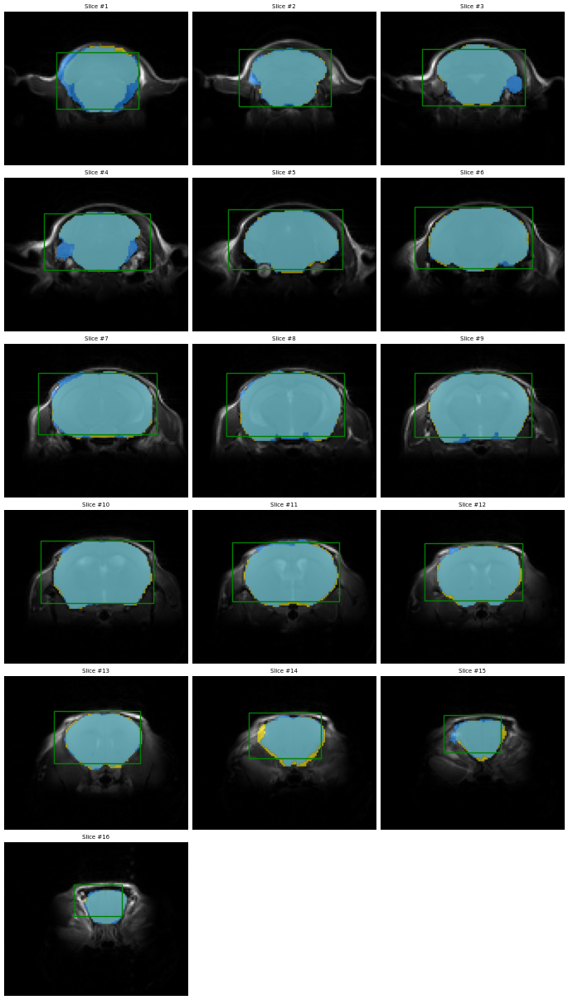

In [6]:
plot_median_scan("D1_T2w")

## D2_T2w

In [7]:
run_experiments("D2_T2w")

    D2_T2w | sub-5463_T2w                                 | Jaccard  Full-Auto 0.9186  Semi-Auto 0.9271  Box 0.8605  Oracle 0.9448 | 4 s
    D2_T2w | sub-5471_T2w                                 | Jaccard  Full-Auto 0.8592  Semi-Auto 0.8807  Box 0.8144  Oracle 0.9307 | 4 s
    D2_T2w | sub-5472_T2w                                 | Jaccard  Full-Auto 0.8936  Semi-Auto 0.9027  Box 0.8042  Oracle 0.9411 | 4 s
    D2_T2w | sub-6085_T2w                                 | Jaccard  Full-Auto 0.9392  Semi-Auto 0.9559  Box 0.8784  Oracle 0.9536 | 4 s
    D2_T2w | sub-6087_T2w                                 | Jaccard  Full-Auto 0.8794  Semi-Auto 0.8993  Box 0.8261  Oracle 0.9253 | 4 s
    D2_T2w | sub-6088_T2w                                 | Jaccard  Full-Auto 0.8759  Semi-Auto 0.9010  Box 0.8325  Oracle 0.9239 | 4 s
    D2_T2w | sub-6092_T2w                                 | Jaccard  Full-Auto 0.8882  Semi-Auto 0.8952  Box 0.8541  Oracle 0.9193 | 4 s
    D2_T2w | sub-6093_T2w                

Median scan of D2_T2w (median Full-Auto Jaccard of 10 scans: 89.89%): sub-5472_T2w | Jaccard  Full-Auto 89.36%  Semi-Auto 90.27%

Full-Auto masks - sub-5472_T2w


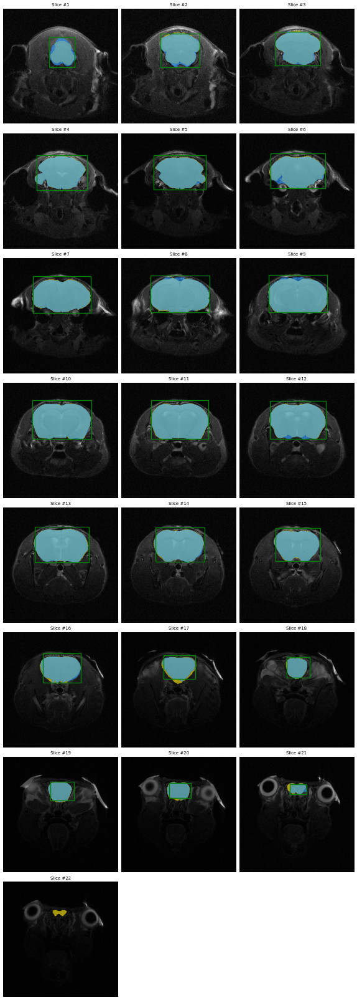


Semi-Auto masks - sub-5472_T2w


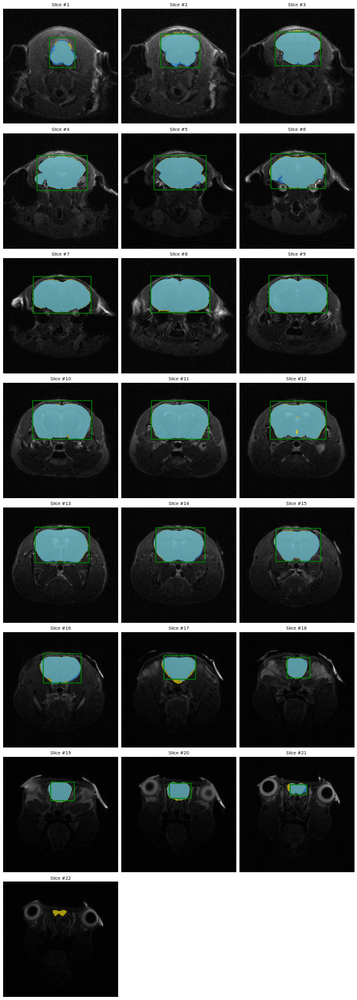

In [8]:
plot_median_scan("D2_T2w")

## D3_T2w

In [9]:
run_experiments("D3_T2w")

    D3_T2w | sub-20190227105648AE0818rsControl1111_T2w    | Jaccard  Full-Auto 0.9444  Semi-Auto 0.9498  Box 0.7841  Oracle 0.9428 | 4 s
    D3_T2w | sub-20190227120644AE0818rsControl1211_T2w    | Jaccard  Full-Auto 0.9390  Semi-Auto 0.9430  Box 0.7738  Oracle 0.9460 | 3 s
    D3_T2w | sub-20190227125730AE0818rsControl1311_T2w    | Jaccard  Full-Auto 0.9493  Semi-Auto 0.9575  Box 0.7894  Oracle 0.9488 | 4 s
    D3_T2w | sub-20190228081325AE0818rsControl1411_T2w    | Jaccard  Full-Auto 0.9213  Semi-Auto 0.9267  Box 0.7362  Oracle 0.9290 | 4 s
    D3_T2w | sub-20190228093749AE0818rsControl2111_T2w    | Jaccard  Full-Auto 0.9494  Semi-Auto 0.9660  Box 0.7946  Oracle 0.9591 | 3 s
    D3_T2w | sub-20190228103014AE0818rsControl1511_T2w    | Jaccard  Full-Auto 0.9424  Semi-Auto 0.9595  Box 0.8258  Oracle 0.9517 | 4 s
    D3_T2w | sub-20190311083410AE0818rsControl1112_T2w    | Jaccard  Full-Auto 0.9263  Semi-Auto 0.9323  Box 0.7781  Oracle 0.9490 | 4 s
    D3_T2w | sub-20190311095840AE0818rsCo

Median scan of D3_T2w (median Full-Auto Jaccard of 12 scans: 94.34%): sub-20190227105648AE0818rsControl1111_T2w | Jaccard  Full-Auto 94.44%  Semi-Auto 94.98%

Full-Auto masks - sub-20190227105648AE0818rsControl1111_T2w


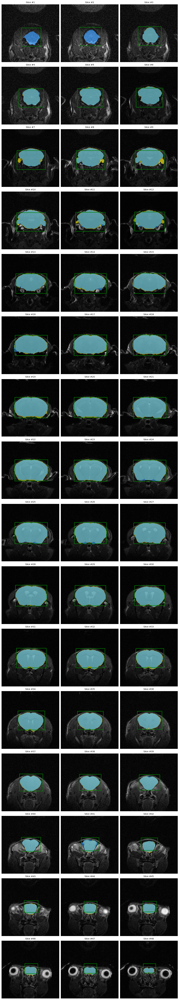


Semi-Auto masks - sub-20190227105648AE0818rsControl1111_T2w


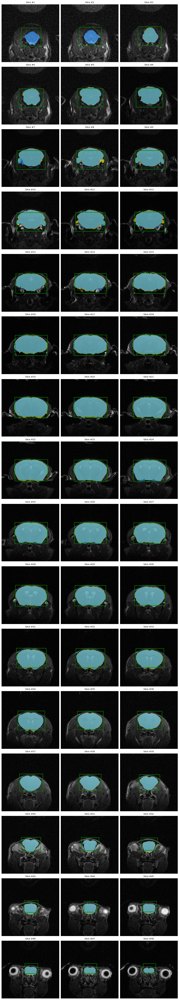

In [10]:
plot_median_scan("D3_T2w")

## D4_T2w

In [11]:
run_experiments("D4_T2w")

    D4_T2w | sub-F030226M26_T2w                           | Jaccard  Full-Auto 0.9575  Semi-Auto 0.9613  Box 0.9383  Oracle 0.9583 | 1 s
    D4_T2w | sub-F040226F17_T2w                           | Jaccard  Full-Auto 0.9532  Semi-Auto 0.9559  Box 0.9324  Oracle 0.9536 | 1 s
    D4_T2w | sub-G040226F18_T2w                           | Jaccard  Full-Auto 0.9607  Semi-Auto 0.9587  Box 0.9236  Oracle 0.9610 | 1 s
    D4_T2w | sub-H040226F19_T2w                           | Jaccard  Full-Auto 0.9543  Semi-Auto 0.9555  Box 0.9034  Oracle 0.9547 | 1 s
    D4_T2w | sub-H050226M22_T2w                           | Jaccard  Full-Auto 0.9551  Semi-Auto 0.9576  Box 0.8290  Oracle 0.9539 | 1 s
    D4_T2w | sub-I040226F20_T2w                           | Jaccard  Full-Auto 0.9488  Semi-Auto 0.9521  Box 0.9186  Oracle 0.9488 | 1 s
    D4_T2w | sub-I050226M23_T2w                           | Jaccard  Full-Auto 0.9352  Semi-Auto 0.9374  Box 0.9120  Oracle 0.9371 | 1 s
    D4_T2w | sub-I070426F31_T2w          

Median scan of D4_T2w (median Full-Auto Jaccard of 15 scans: 94.91%): sub-N090426F30_T2w | Jaccard  Full-Auto 94.91%  Semi-Auto 96.07%

Full-Auto masks - sub-N090426F30_T2w


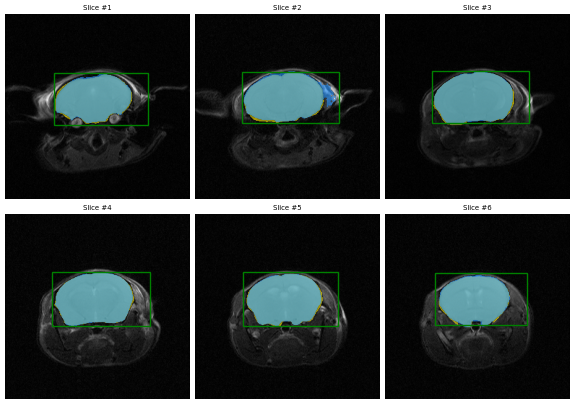


Semi-Auto masks - sub-N090426F30_T2w


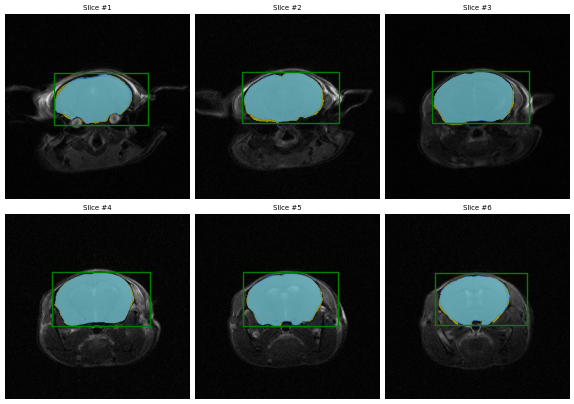

In [12]:
plot_median_scan("D4_T2w")

## D4_T2starw

In [13]:
run_experiments("D4_T2starw")

D4_T2starw | sub-F030226M26_T2starw                       | Jaccard  Full-Auto 0.9327  Semi-Auto 0.9393  Box 0.8220  Oracle 0.9418 | 0 s
D4_T2starw | sub-F040226F17_T2starw                       | Jaccard  Full-Auto 0.9238  Semi-Auto 0.9336  Box 0.8526  Oracle 0.9193 | 0 s
D4_T2starw | sub-G040226F18_T2starw                       | Jaccard  Full-Auto 0.9339  Semi-Auto 0.9421  Box 0.8397  Oracle 0.9335 | 0 s
D4_T2starw | sub-H040226F19_T2starw                       | Jaccard  Full-Auto 0.9225  Semi-Auto 0.9288  Box 0.8421  Oracle 0.9248 | 0 s
D4_T2starw | sub-H050226M22_T2starw                       | Jaccard  Full-Auto 0.9307  Semi-Auto 0.9368  Box 0.8541  Oracle 0.9256 | 0 s
D4_T2starw | sub-I040226F20_T2starw                       | Jaccard  Full-Auto 0.9149  Semi-Auto 0.9235  Box 0.7868  Oracle 0.9232 | 0 s
D4_T2starw | sub-I050226M23_T2starw                       | Jaccard  Full-Auto 0.8974  Semi-Auto 0.9033  Box 0.8096  Oracle 0.8972 | 0 s
D4_T2starw | sub-I070426F31_T2starw      

Median scan of D4_T2starw (median Full-Auto Jaccard of 15 scans: 92.38%): sub-F040226F17_T2starw | Jaccard  Full-Auto 92.38%  Semi-Auto 93.36%

Full-Auto masks - sub-F040226F17_T2starw


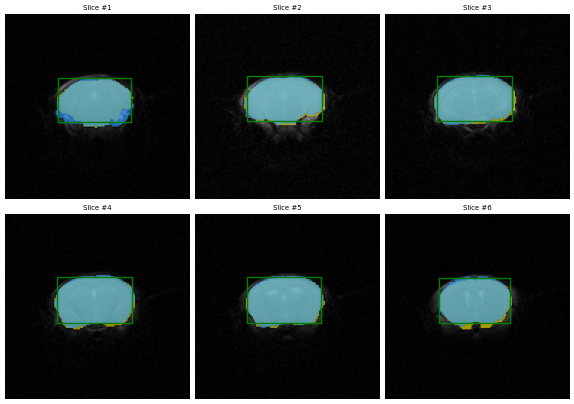


Semi-Auto masks - sub-F040226F17_T2starw


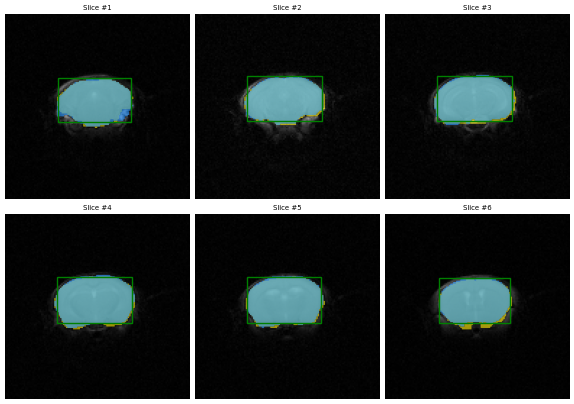

In [14]:
plot_median_scan("D4_T2starw")

## D4_DWI

In [15]:
run_experiments("D4_DWI")

    D4_DWI | sub-F030226M26_dwi                           | Jaccard  Full-Auto 0.9313  Semi-Auto 0.9353  Box 0.8668  Oracle 0.9286 | 0 s
    D4_DWI | sub-F040226F17_dwi                           | Jaccard  Full-Auto 0.9289  Semi-Auto 0.9326  Box 0.8691  Oracle 0.9072 | 0 s
    D4_DWI | sub-G040226F18_dwi                           | Jaccard  Full-Auto 0.9238  Semi-Auto 0.9332  Box 0.8469  Oracle 0.9227 | 0 s
    D4_DWI | sub-H040226F19_dwi                           | Jaccard  Full-Auto 0.9206  Semi-Auto 0.9331  Box 0.8454  Oracle 0.9107 | 0 s
    D4_DWI | sub-H050226M22_dwi                           | Jaccard  Full-Auto 0.9335  Semi-Auto 0.9350  Box 0.8406  Oracle 0.9402 | 0 s
    D4_DWI | sub-I040226F20_dwi                           | Jaccard  Full-Auto 0.9414  Semi-Auto 0.9423  Box 0.8315  Oracle 0.9323 | 0 s
    D4_DWI | sub-I050226M23_dwi                           | Jaccard  Full-Auto 0.9259  Semi-Auto 0.9335  Box 0.8467  Oracle 0.9243 | 0 s
    D4_DWI | sub-I070426F31_dwi          

Median scan of D4_DWI (median Full-Auto Jaccard of 15 scans: 93.07%): sub-P080426M35_dwi | Jaccard  Full-Auto 93.07%  Semi-Auto 94.21%

Full-Auto masks - sub-P080426M35_dwi


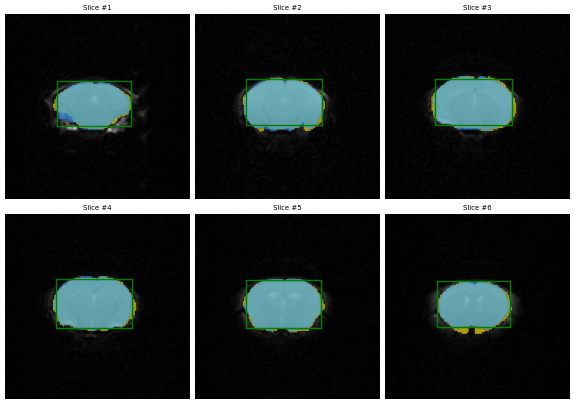


Semi-Auto masks - sub-P080426M35_dwi


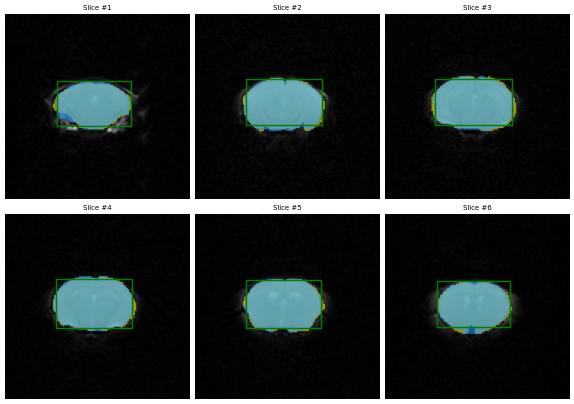

In [16]:
plot_median_scan("D4_DWI")

## D5_DWI

In [17]:
run_experiments("D5_DWI")

    D5_DWI | sub-B011223_dwi                              | Jaccard  Full-Auto 0.9023  Semi-Auto 0.9278  Box 0.6782  Oracle 0.9200 | 0 s
    D5_DWI | sub-B021023_dwi                              | Jaccard  Full-Auto 0.9304  Semi-Auto 0.9424  Box 0.7942  Oracle 0.9393 | 0 s
    D5_DWI | sub-B030222_dwi                              | Jaccard  Full-Auto 0.9098  Semi-Auto 0.9223  Box 0.7400  Oracle 0.9196 | 0 s
    D5_DWI | sub-B031023_dwi                              | Jaccard  Full-Auto 0.9244  Semi-Auto 0.9279  Box 0.7203  Oracle 0.9255 | 0 s
    D5_DWI | sub-B041023_dwi                              | Jaccard  Full-Auto 0.9284  Semi-Auto 0.9349  Box 0.7551  Oracle 0.9305 | 0 s
    D5_DWI | sub-B050225_dwi                              | Jaccard  Full-Auto 0.9256  Semi-Auto 0.9408  Box 0.7971  Oracle 0.9367 | 0 s
    D5_DWI | sub-B060225_dwi                              | Jaccard  Full-Auto 0.9273  Semi-Auto 0.9385  Box 0.7443  Oracle 0.9453 | 0 s
    D5_DWI | sub-B070225_dwi             

Median scan of D5_DWI (median Full-Auto Jaccard of 82 scans: 92.48%): sub-B100624_dwi | Jaccard  Full-Auto 92.45%  Semi-Auto 92.96%

Full-Auto masks - sub-B100624_dwi


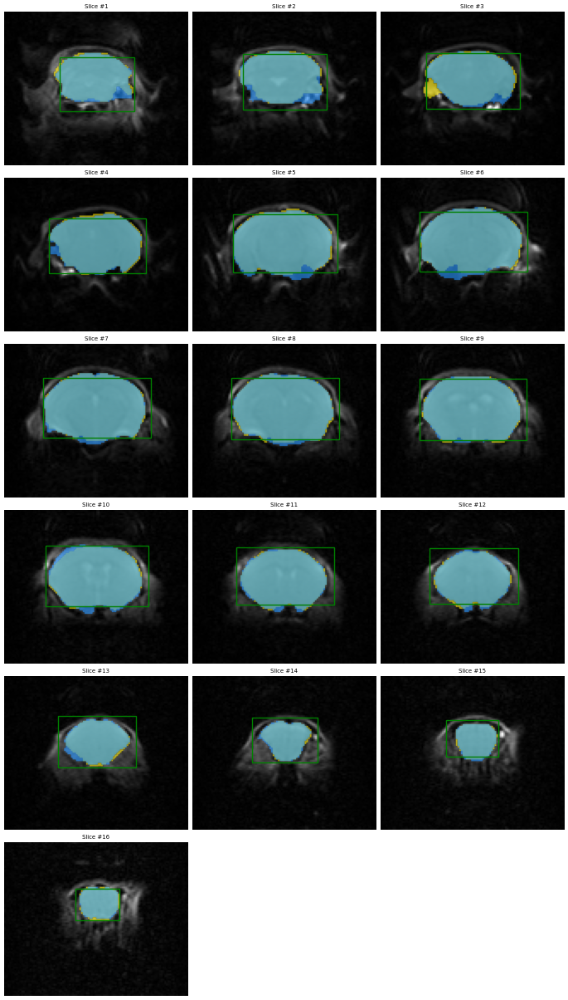


Semi-Auto masks - sub-B100624_dwi


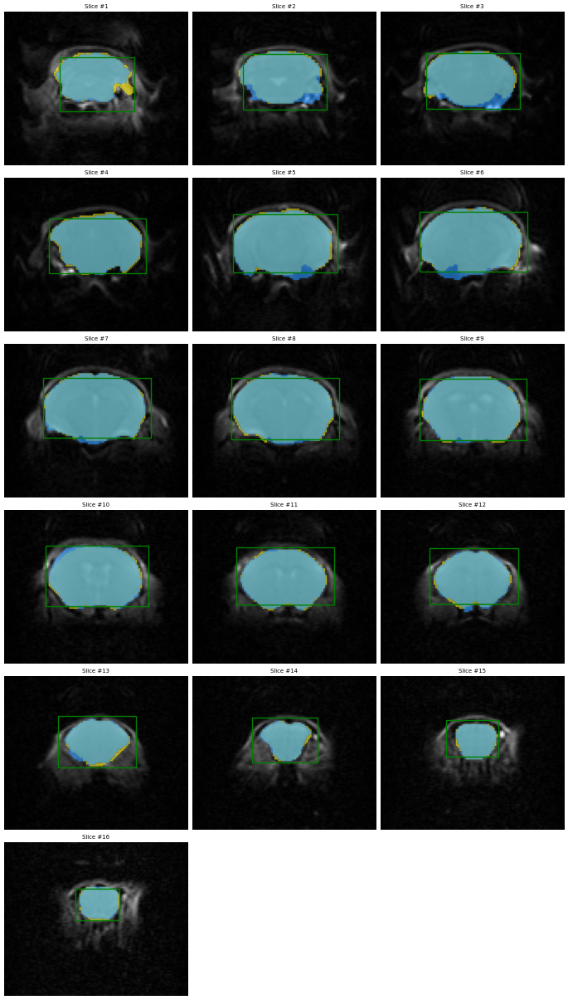

In [18]:
plot_median_scan("D5_DWI")

## D6_T2w

In [19]:
run_experiments("D6_T2w")

    D6_T2w | sub-IN2168024_ses-01_T2w                     | Jaccard  Full-Auto 0.9509  Semi-Auto 0.9596  Box 0.7227  Oracle 0.9579 | 2 s
    D6_T2w | sub-IN2168024_ses-02_T2w                     | Jaccard  Full-Auto 0.9406  Semi-Auto 0.9507  Box 0.7297  Oracle 0.9455 | 2 s
    D6_T2w | sub-IN2168024_ses-03_T2w                     | Jaccard  Full-Auto 0.9367  Semi-Auto 0.9467  Box 0.7329  Oracle 0.9390 | 2 s
    D6_T2w | sub-IN2168024_ses-04_T2w                     | Jaccard  Full-Auto 0.9479  Semi-Auto 0.9524  Box 0.8845  Oracle 0.9485 | 2 s
    D6_T2w | sub-IN2168024_ses-05_T2w                     | Jaccard  Full-Auto 0.9265  Semi-Auto 0.9451  Box 0.6776  Oracle 0.9466 | 2 s
    D6_T2w | sub-IN2168024_ses-06_T2w                     | Jaccard  Full-Auto 0.9062  Semi-Auto 0.9408  Box 0.6478  Oracle 0.9379 | 2 s
    D6_T2w | sub-IN2168324_ses-01_T2w                     | Jaccard  Full-Auto 0.9617  Semi-Auto 0.9663  Box 0.7522  Oracle 0.9617 | 2 s
    D6_T2w | sub-IN2168324_ses-02_T2w    

Median scan of D6_T2w (median Full-Auto Jaccard of 96 scans: 93.00%): sub-IN2388824_ses-06_T2w | Jaccard  Full-Auto 93.01%  Semi-Auto 93.87%

Full-Auto masks - sub-IN2388824_ses-06_T2w


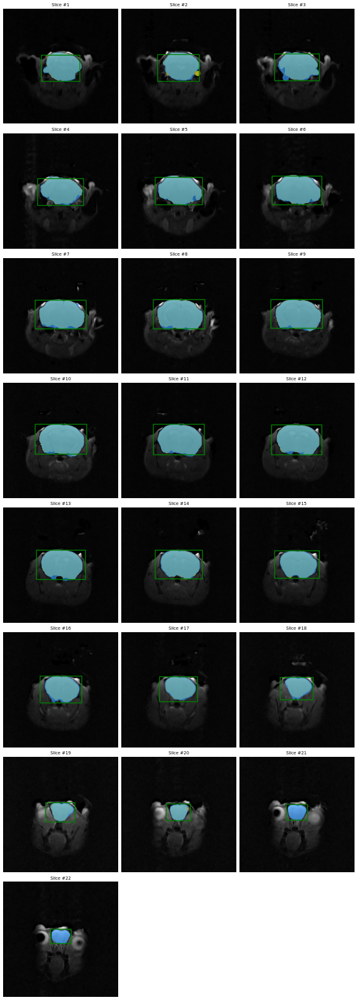


Semi-Auto masks - sub-IN2388824_ses-06_T2w


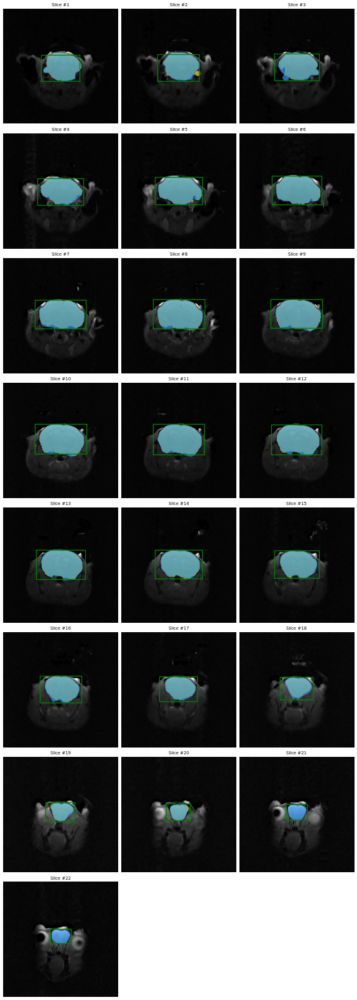

In [20]:
plot_median_scan("D6_T2w")

## D6_BOLD

In [21]:
run_experiments("D6_BOLD")

   D6_BOLD | sub-IN2168024_ses-01_bold                    | Jaccard  Full-Auto 0.8989  Semi-Auto 0.9157  Box 0.7138  Oracle 0.9239 | 0 s
   D6_BOLD | sub-IN2168024_ses-02_bold                    | Jaccard  Full-Auto 0.8887  Semi-Auto 0.9013  Box 0.6757  Oracle 0.9225 | 0 s
   D6_BOLD | sub-IN2168024_ses-03_bold                    | Jaccard  Full-Auto 0.8796  Semi-Auto 0.9012  Box 0.7385  Oracle 0.9193 | 0 s
   D6_BOLD | sub-IN2168024_ses-04_bold                    | Jaccard  Full-Auto 0.8699  Semi-Auto 0.9006  Box 0.7362  Oracle 0.9105 | 0 s
   D6_BOLD | sub-IN2168024_ses-05_bold                    | Jaccard  Full-Auto 0.8727  Semi-Auto 0.8979  Box 0.7316  Oracle 0.9151 | 0 s
   D6_BOLD | sub-IN2168024_ses-06_bold                    | Jaccard  Full-Auto 0.8946  Semi-Auto 0.9147  Box 0.7671  Oracle 0.9145 | 0 s
   D6_BOLD | sub-IN2168324_ses-02_bold                    | Jaccard  Full-Auto 0.9042  Semi-Auto 0.9268  Box 0.7223  Oracle 0.9205 | 0 s
   D6_BOLD | sub-IN2168324_ses-03_bold   

Median scan of D6_BOLD (median Full-Auto Jaccard of 95 scans: 89.60%): sub-IN2388224_ses-05_bold | Jaccard  Full-Auto 89.60%  Semi-Auto 90.60%

Full-Auto masks - sub-IN2388224_ses-05_bold


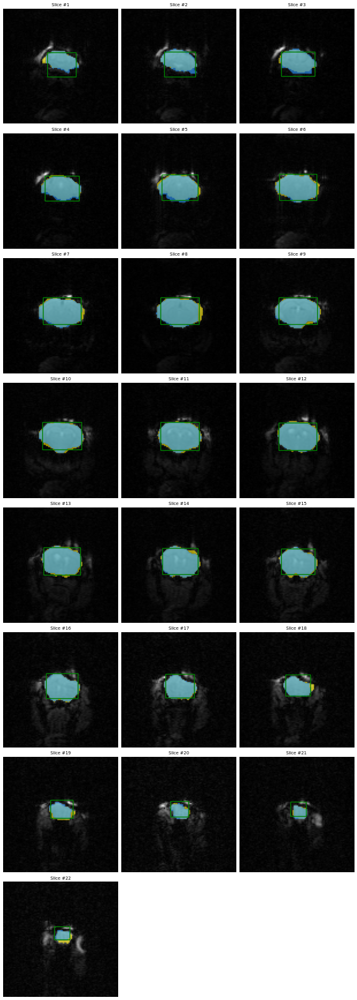


Semi-Auto masks - sub-IN2388224_ses-05_bold


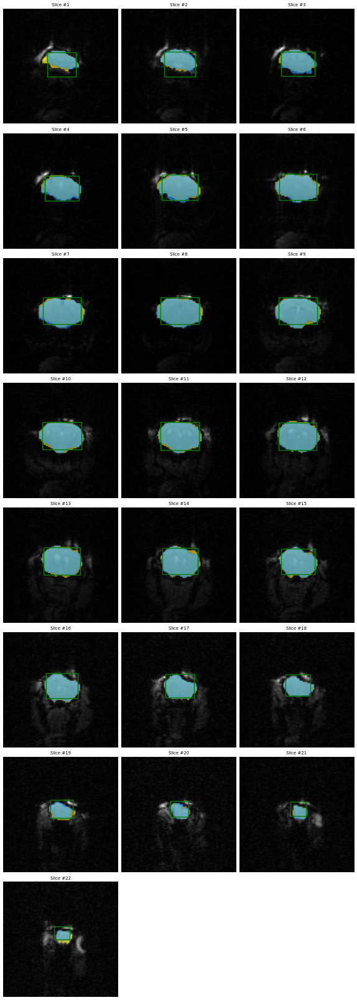

In [22]:
plot_median_scan("D6_BOLD")

## D7_T2w

In [23]:
run_experiments("D7_T2w")

    D7_T2w | sub-BF001_T2w                                | Jaccard  Full-Auto 0.9672  Semi-Auto 0.9694  Box 0.9031  Oracle 0.9681 | 5 s
    D7_T2w | sub-BF003_T2w                                | Jaccard  Full-Auto 0.9596  Semi-Auto 0.9633  Box 0.8913  Oracle 0.9630 | 5 s
    D7_T2w | sub-BF004_T2w                                | Jaccard  Full-Auto 0.9219  Semi-Auto 0.9528  Box 0.8040  Oracle 0.9267 | 5 s
    D7_T2w | sub-BF005_T2w                                | Jaccard  Full-Auto 0.9666  Semi-Auto 0.9673  Box 0.8441  Oracle 0.9662 | 5 s
    D7_T2w | sub-BF006_T2w                                | Jaccard  Full-Auto 0.9507  Semi-Auto 0.9669  Box 0.8296  Oracle 0.9642 | 5 s
    D7_T2w | sub-BF007_T2w                                | Jaccard  Full-Auto 0.9729  Semi-Auto 0.9739  Box 0.9313  Oracle 0.9730 | 5 s
    D7_T2w | sub-BF008_T2w                                | Jaccard  Full-Auto 0.9614  Semi-Auto 0.9708  Box 0.8349  Oracle 0.9689 | 5 s
    D7_T2w | sub-BF009_T2w               

Median scan of D7_T2w (median Full-Auto Jaccard of 16 scans: 96.05%): sub-BF003_T2w | Jaccard  Full-Auto 95.96%  Semi-Auto 96.33%

Full-Auto masks - sub-BF003_T2w


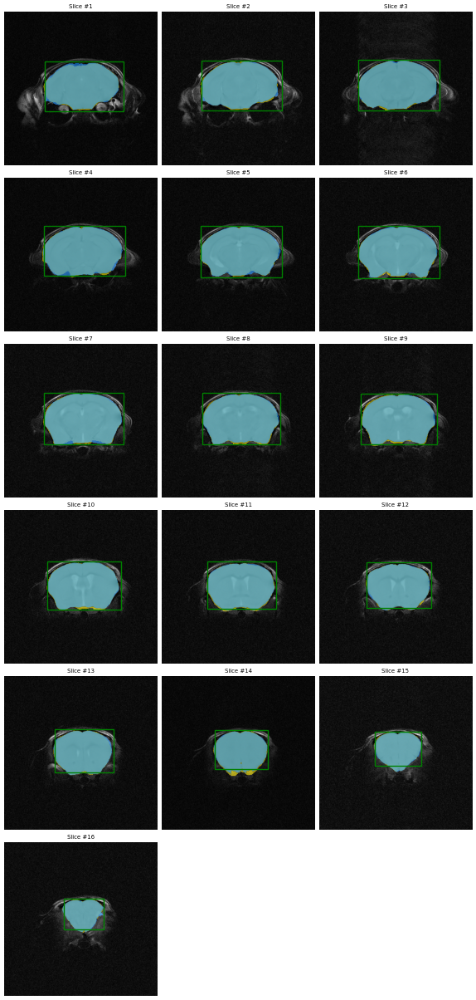


Semi-Auto masks - sub-BF003_T2w


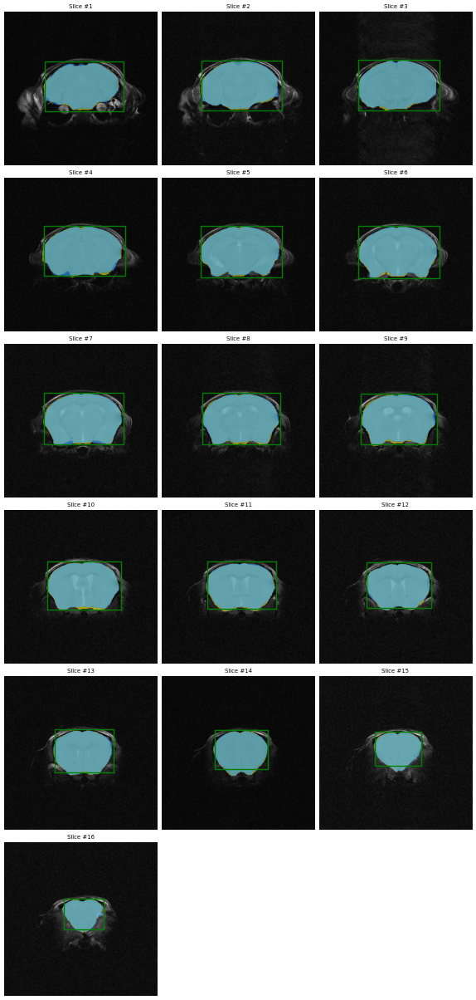

In [24]:
plot_median_scan("D7_T2w")

In [25]:
save_results("exp_samson")

Saved 29992 slice rows and 1636 subject rows to results/exp_samson_*.csv


## Reproducibility check
With `REGENERATE = True`, comparison of the masks (mapped back to the stored orientation) and boxes generated here with those of the full run (`outputs/masks/samson_*`, `outputs/boxes`): identical scans / scans. Then the largest absolute difference between the scan metrics computed here and those of the full run (`results/subjects.csv`, written by `run_all.py --evaluate`; box: `results/boxes.csv`).

In [26]:
if REGENERATE:
    checks = pd.DataFrame(check_results)
    table = checks.groupby(["check", "dataset"], sort=False).identical.agg(lambda x: f"{x.sum()}/{len(x)}").unstack()[DATASETS].fillna("")
    table["All"] = checks.groupby("check", sort=False).identical.agg(lambda x: f"{x.sum()}/{len(x)}")
    table["differing_voxels"] = checks.groupby("check", sort=False).differing_voxels.sum(min_count=1)
    display(table)
else:
    print("REGENERATE = False: masks and boxes loaded from outputs/ (not regenerated, so not compared here).")

REGENERATE = False: masks and boxes loaded from outputs/ (not regenerated, so not compared here).


In [27]:
keys = ["dataset", "contrast", "subject", "session"]
columns = ["n_slices", "accuracy", "jaccard", "dice", "failed_slices", "jaccard_3d", "dice_3d", "hd95_mm", "volume_bias_pct"]
ours = pd.DataFrame(subject_results)
full_run = pd.read_csv(pjoin(results_path, "subjects.csv"), dtype={"session": str}).fillna({"session": ""})
boxes_full_run = (pd.read_csv(pjoin(results_path, "boxes.csv"), dtype={"session": str}).fillna({"session": ""})
                  .groupby(keys, as_index=False).agg(n_slices=("slice", "size"), accuracy=("box_accuracy", "mean"),
                                                     jaccard=("box_jaccard", "mean"), dice=("box_dice", "mean")))
rows = []
for method in ("full_auto", "semi_auto", "oracle", "box"):
    reference = boxes_full_run if method == "box" else full_run[full_run.tool == f"samson_{method}"]
    merged = ours[ours.method == method].merge(reference, on=keys, suffixes=("", "_full_run"))
    rows.append(dict(method=method, scans=f"{len(merged)}/{(ours.method == method).sum()}",
                     **{c: (merged[c] - merged[c + "_full_run"]).abs().max() for c in columns if c + "_full_run" in merged}))
pd.DataFrame(rows).set_index("method")

,scans,n_slices,accuracy,jaccard,dice,failed_slices,jaccard_3d,dice_3d,hd95_mm,volume_bias_pct
method,,,,,,,,,,
full_auto,409/409,0,1.421085e-14,1.110223e-16,1.110223e-16,0.0,1.110223e-16,1.110223e-16,1.110223e-16,1.776357e-15
semi_auto,409/409,0,1.421085e-14,1.110223e-16,1.110223e-16,0.0,1.110223e-16,1.110223e-16,2.220446e-16,1.776357e-15
oracle,409/409,0,1.421085e-14,1.110223e-16,1.110223e-16,0.0,1.110223e-16,1.110223e-16,8.326673e-17,8.881784e-16
box,409/409,0,2.842171e-14,2.220446e-16,3.330669e-16,NaN,NaN,NaN,NaN,NaN
